In [1]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
adult = fetch_ucirepo(id=2)
X = adult.data.features
y = (adult.data.targets["income"].str.strip().str.rstrip(".") == ">50K").astype(int)
print(X.shape, y.mean())

(48842, 14) 0.23928176569346055


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)

In [3]:
print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.mean(), y_val.mean(), y_test.mean())

(29305, 14) (9768, 14) (9769, 14)
0.23927657396348745 0.23925061425061425 0.23932848807452145


In [4]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = make_column_selector(dtype_include="number")
cat_cols = make_column_selector(dtype_exclude="number")

preprocess = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

logreg = Pipeline([("prep", clone(preprocess)),
                   ("model", LogisticRegression(max_iter=1000))])
gb = Pipeline([("prep", clone(preprocess)),
               ("model", HistGradientBoostingClassifier(random_state=42))])

logreg.fit(X_train, y_train)
gb.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a44431a9ba0>),
                                                 ('cat',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a44431ec950>)])),
                ('model', HistGradientBoostingClassifier(random_state=42))])

In [6]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

for name, m in [("Logistic Regression", logreg), ("Gradient Boosting", gb)]:
    pred = m.predict(X_val)
    prob = m.predict_proba(X_val)[:, 1]
    print(name,
          "| accuracy:", round(accuracy_score(y_val, pred), 3),
          "| F1:", round(f1_score(y_val, pred), 3),
          "| AUC:", round(roc_auc_score(y_val, prob), 3))

Logistic Regression | accuracy: 0.852 | F1: 0.656 | AUC: 0.907
Gradient Boosting | accuracy: 0.874 | F1: 0.715 | AUC: 0.93


In [7]:
import numpy as np
from sklearn.isotonic import IsotonicRegression

p_val = gb.predict_proba(X_val)[:, 1]
p_test = gb.predict_proba(X_test)[:, 1]

iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(p_val, y_val)
p_test_cal = iso.predict(p_test)

In [8]:
def ece(y_true, p, bins=10):
    y_true = np.asarray(y_true)
    idx = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    total = 0
    for b in range(bins):
        mask = idx == b
        if mask.sum() > 0:
            total += mask.mean() * abs(y_true[mask].mean() - p[mask].mean())
    return total

print("ECE before:", round(ece(y_test, p_test), 4))
print("ECE after: ", round(ece(y_test, p_test_cal), 4))

ECE before: 0.0136
ECE after:  0.0148


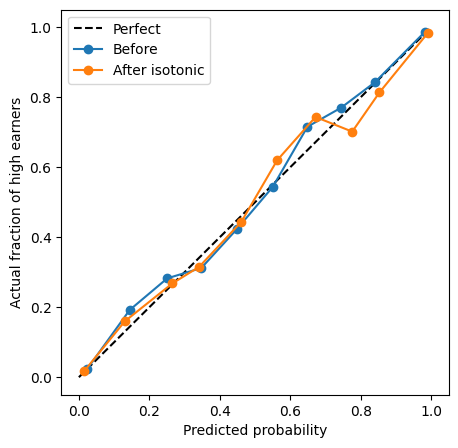

In [9]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
for label, p in [("Before", p_test), ("After isotonic", p_test_cal)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10)
    plt.plot(mean_p, frac, marker="o", label=label)
plt.xlabel("Predicted probability")
plt.ylabel("Actual fraction of high earners")
plt.legend()
plt.savefig("reliability.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
import pandas as pd

df = X_test.copy()
df["y"] = y_test.values
df["p"] = p_test
df["pred"] = (p_test >= 0.5).astype(int)
df["age_band"] = pd.cut(df["age"], bins=[16, 25, 35, 45, 55, 65, 100],
                        labels=["17-25", "26-35", "36-45", "46-55", "56-65", "65+"])

In [11]:
def slice_report(col):
    rows = []
    for val, g in df.groupby(col, observed=True):
        if len(g) < 100:
            continue
        rows.append({col: val,
                     "n": len(g),
                     "actual_rate": g["y"].mean(),
                     "avg_predicted": g["p"].mean(),
                     "accuracy": (g["pred"] == g["y"]).mean(),
                     "recall": g.loc[g["y"] == 1, "pred"].mean()})
    return pd.DataFrame(rows).round(3)

In [12]:
print(slice_report("sex"), "\n")
print(slice_report("age_band"), "\n")
print(slice_report("education"))

      sex     n  actual_rate  avg_predicted  accuracy  recall
0  Female  3298        0.114          0.111     0.939   0.592
1    Male  6471        0.303          0.294     0.844   0.665 

  age_band     n  actual_rate  avg_predicted  accuracy  recall
0    17-25  1982        0.015          0.018     0.990   0.310
1    26-35  2572        0.198          0.185     0.880   0.539
2    36-45  2372        0.358          0.347     0.821   0.692
3    46-55  1625        0.369          0.369     0.836   0.741
4    56-65   864        0.314          0.298     0.825   0.613
5      65+   354        0.223          0.217     0.879   0.582 

       education     n  actual_rate  avg_predicted  accuracy  recall
0           10th   275        0.084          0.057     0.927   0.130
1           11th   368        0.043          0.048     0.965   0.312
2           12th   146        0.103          0.096     0.938   0.400
3        7th-8th   201        0.085          0.069     0.940   0.294
4            9th   154  

In [13]:
for name, m in [("Logistic Regression", logreg), ("Gradient Boosting", gb)]:
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    print(name,
          "| accuracy:", round(accuracy_score(y_test, pred), 3),
          "| F1:", round(f1_score(y_test, pred), 3),
          "| AUC:", round(roc_auc_score(y_test, prob), 3))

Logistic Regression | accuracy: 0.855 | F1: 0.662 | AUC: 0.907
Gradient Boosting | accuracy: 0.876 | F1: 0.716 | AUC: 0.928


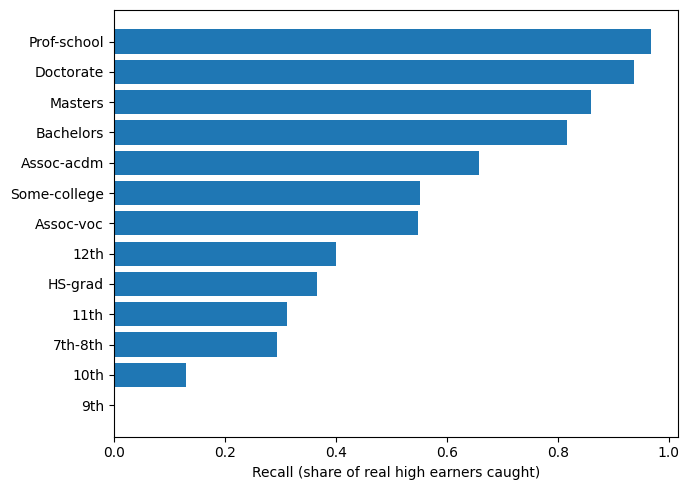

In [14]:
edu = slice_report("education").sort_values("recall")
plt.figure(figsize=(7, 5))
plt.barh(edu["education"], edu["recall"])
plt.xlabel("Recall (share of real high earners caught)")
plt.tight_layout()
plt.savefig("recall_by_education.png", dpi=150)
plt.show()